# Predicción de contratación de depósitos bancarios

## 1. Carga y descripción del dataset

Se utiliza `bank-full.csv` del conjunto [Bank Marketing de UCI](https://archive.ics.uci.edu/dataset/222/bank+marketing). El archivo contiene **45,211 registros y 17 columnas**: 16 características y la variable objetivo `y`. El objetivo del experimento es estimar qué clientes podrían contratar un depósito para priorizar llamadas futuras. El archivo se lee con separador de punto y coma (`;`).

| Variable | Tipo en Pandas | Significado |
| --- | --- | --- |
| `age` | `int64` | Edad del cliente. |
| `job` | `object` | Ocupación. |
| `marital` | `object` | Estado civil. |
| `education` | `object` | Nivel educativo. |
| `default` | `object` | Si tiene un crédito en incumplimiento. |
| `balance` | `int64` | Saldo anual promedio en euros. |
| `housing` | `object` | Si tiene préstamo de vivienda. |
| `loan` | `object` | Si tiene préstamo personal. |
| `contact` | `object` | Medio de contacto utilizado. |
| `day` | `int64` | Día del mes del último contacto. |
| `month` | `object` | Mes del último contacto. |
| `duration` | `int64` | Duración de la última llamada en segundos. |
| `campaign` | `int64` | Número de contactos durante la campaña actual. |
| `pdays` | `int64` | Días desde un contacto de una campaña anterior; `-1` indica que no hubo uno. |
| `previous` | `int64` | Número de contactos previos a esta campaña. |
| `poutcome` | `object` | Resultado de una campaña anterior. |
| `y` | `object` | Variable objetivo: `yes` si contrató el depósito; `no` si no. |

En total se cargaron **7 columnas numéricas** (`int64`) y **10 columnas de texto** (`object`), incluida la variable objetivo.

In [4]:
%pip -q install mlflow

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import sqlite3
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import precision_recall_curve
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from pandas.api.types import CategoricalDtype
import subprocess
from urllib.parse import urlparse
from google.colab import output
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay
)
import mlflow
import mlflow.sklearn

In [6]:
path = "/content/bank-full.csv"
df = pd.read_csv(path, sep=";")

print(df.shape)
display(df.head())
df.info()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [7]:
display(df.describe(include="all").T)

print("Distribución de la variable objetivo:")
display(df["y"].value_counts())
display(df["y"].value_counts(normalize=True).mul(100).round(2))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


Distribución de la variable objetivo:


,count
y,
no,39922
yes,5289


,proportion
y,
no,88.3
yes,11.7


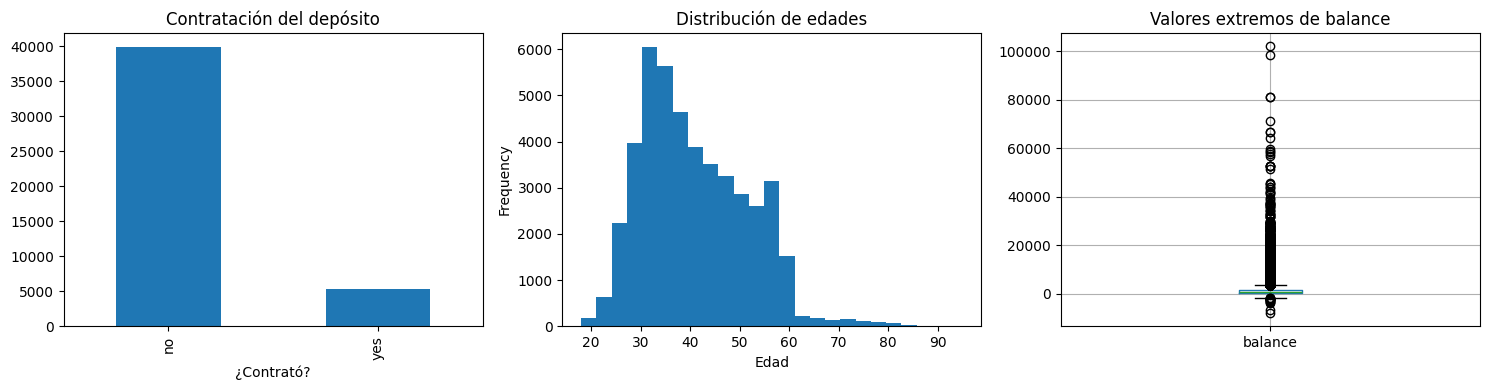

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["y"].value_counts().plot.bar(ax=axes[0], title="Contratación del depósito")
axes[0].set_xlabel("¿Contrató?")

df["age"].plot.hist(bins=25, ax=axes[1], title="Distribución de edades")
axes[1].set_xlabel("Edad")

df.boxplot(column="balance", ax=axes[2])
axes[2].set_title("Valores extremos de balance")

plt.tight_layout()
plt.show()

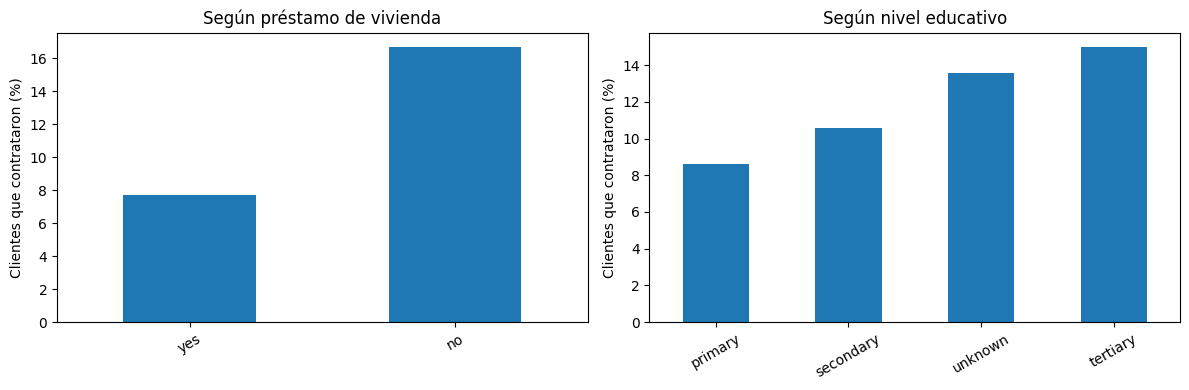

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, columna, titulo in [
    (axes[0], "housing", "Según préstamo de vivienda"),
    (axes[1], "education", "Según nivel educativo")
]:
    tasas = pd.crosstab(df[columna], df["y"], normalize="index")["yes"] * 100
    tasas.sort_values().plot.bar(ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("Clientes que contrataron (%)")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 2. Análisis exploratorio (EDA)

Las estadísticas descriptivas muestran una edad mediana de 39 años (mínimo 18, máximo 95). El saldo `balance` tiene mediana de 448 euros y media de 1,362 euros; la diferencia, junto con el diagrama de caja, muestra una distribución con valores altos poco frecuentes.

La variable objetivo está desbalanceada: 39,922 clientes (88.30 %) no contrataron el depósito y 5,289 (11.70 %) sí lo hicieron. Por ello, la exactitud por sí sola puede dar una impresión engañosa del desempeño. En la evaluación revisaremos también precisión, recall, F1 y la matriz de confusión.

Las gráficas de relaciones muestran que la proporción observada de contratación es mayor entre clientes sin préstamo de vivienda (aproximadamente 17 %) que entre quienes sí lo tienen (aproximadamente 8 %). También es mayor en el grupo de educación `tertiary` que en `primary`. Estas diferencias describen asociaciones en la muestra; no demuestran que las características causen la contratación.

In [10]:
columnas_texto = df.select_dtypes(include="object").columns
conteo = df[columnas_texto].eq("unknown").sum()

resumen_unknown = pd.DataFrame({
    "cantidad": conteo,
    "porcentaje": (conteo / len(df) * 100).round(2)
})

display(resumen_unknown[resumen_unknown["cantidad"] > 0]
        .sort_values("porcentaje", ascending=False))

,cantidad,porcentaje
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64


In [11]:
print("Valores nulos reales:", df.isna().sum().sum())
print("Filas exactamente duplicadas:", df.duplicated().sum())

display(
    df[["age", "balance", "campaign", "previous"]]
    .describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.99])
    .T
)


Valores nulos reales: 0
Filas exactamente duplicadas: 0


,count,mean,std,min,1%,25%,50%,75%,99%,max
age,45211.0,40.936210,10.618762,18.0,23.0,33.0,39.0,48.0,71.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,-627.0,72.0,448.0,1428.0,13164.9,102127.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,1.0,2.0,3.0,16.0,63.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,0.0,8.9,275.0


In [12]:
# Cuantificar extremos sin asumir que son errores
for columna in ["age", "balance"]:
    q1, q3 = df[columna].quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    extremos = ((df[columna] < limite_inferior) |
                (df[columna] > limite_superior)).sum()
    print(f"{columna}: límites IQR [{limite_inferior:.1f}, {limite_superior:.1f}], "
          f"extremos = {extremos} ({extremos / len(df) * 100:.2f} %)")

# En previous los cuartiles son cero; el IQR no distingue casos raros.
p99_previous = df["previous"].quantile(0.99)
print(f"previous: percentil 99 = {p99_previous:.1f}; "
      f"valores por encima = {(df['previous'] > p99_previous).sum()}")
display(df.nlargest(5, "previous")[["age", "previous", "pdays", "y"]])

age: límites IQR [10.5, 70.5], extremos = 487 (1.08 %)
balance: límites IQR [-1962.0, 3462.0], extremos = 4729 (10.46 %)
previous: percentil 99 = 8.9; valores por encima = 453


,age,previous,pdays,y
29182,40,275,262,no
38326,46,58,353,yes
44089,37,55,776,yes
28886,31,51,256,no
44822,27,41,778,no


**Decisión sobre valores extremos.** La regla de 1.5 veces el IQR marca 487 edades (1.08 %) y 4,729 saldos (10.46 %). En `previous`, donde los cuartiles son cero, 453 registros superan el percentil 99 (8.9 contactos). Estos criterios detectan valores poco frecuentes, pero no prueban errores. Conservamos las observaciones porque una edad avanzada, un saldo negativo o muchos contactos previos pueden ser datos reales. No se recortan ni eliminan filas en este baseline; la sensibilidad del escalado y del modelo a estos valores queda como limitación a revisar después.

In [13]:
columnas_excluir = [
    "contact", "day", "month", "duration", "campaign", "poutcome"
]

df_modelo = df.drop(columns=columnas_excluir).copy()

print("Datos para el modelo:", df_modelo.shape)
display(df_modelo.head())

Datos para el modelo: (45211, 11)


,age,job,marital,education,default,balance,housing,loan,pdays,previous,y
0,58,management,married,tertiary,no,2143,yes,no,-1,0,no
1,44,technician,single,secondary,no,29,yes,no,-1,0,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,-1,0,no
3,47,blue-collar,married,unknown,no,1506,yes,no,-1,0,no
4,33,unknown,single,unknown,no,1,no,no,-1,0,no


## 3. Limpieza y selección de variables

- **Valores faltantes:** no hay celdas nulas (`NaN`). Se revisó también la categoría `unknown`: aparece en `poutcome` (81.75 %), `contact` (28.80 %), `education` (4.11 %) y `job` (0.64 %). En `job` y `education` se conserva como categoría explícita; imputarla con la moda supondría información que no conocemos.
- **Duplicados:** no hay filas exactamente duplicadas, por lo que no se eliminó ningún registro.
- **Tipos:** las siete columnas numéricas se cargaron como `int64` y las categorías como `object`. No se detectaron tipos incorrectos. `pdays = -1` representa ausencia de contacto previo; no es un error de captura.
- **Valores extremos:** `age` llega a 95 años; `balance` va de -8,019 a 102,127 euros, y `previous` llega a 275 contactos (percentil 99: 8.9). Se identificaron estos extremos, pero no se eliminaron filas porque no hay evidencia de que sean errores. Se tendrá en cuenta su efecto al preparar el modelo.
- **Variables excluidas del modelo:** se retiraron `contact`, `day`, `month`, `duration` y `campaign` porque describen el contacto o la campaña actual y el objetivo es priorizar clientes antes de llamar. También se retiró `poutcome` por su 81.75 % de resultados desconocidos. El análisis original permanece en `df`; la tabla para modelado, `df_modelo`, conserva 45,211 registros y 11 columnas.

## 4. Modelo base

El problema es de **clasificación binaria**: `y = 1` significa que el cliente contrató y `y = 0` que no contrató. Se entrenará una **regresión logística** con los datos disponibles antes de la llamada. Se reservará el 20 % de los registros para prueba mediante una división estratificada, con semilla 42, para conservar la proporción de la clase positiva.

Las variables numéricas se estandarizarán y las categóricas se codificarán con *one-hot encoding* dentro de un `Pipeline`. Así, la preparación se ajusta solo con el conjunto de entrenamiento y luego se aplica al de prueba. Como referencia adicional, se entrenará un clasificador que siempre predice la clase mayoritaria (`no`); esto ayuda a interpretar el efecto del desbalance.

**Justificación del modelo:** la regresión logística es una primera opción sencilla para una respuesta binaria, entrega probabilidades para ordenar clientes y permite analizar sus coeficientes más adelante. Se eligió *antes* de observar el resultado de prueba, como referencia reproducible del flujo. La actividad pide entrenar un modelo base; no exige seleccionar el mejor entre varios algoritmos. El clasificador que siempre predice `no` se incluye únicamente como referencia para interpretar las métricas frente al desbalance.

In [14]:
# Objetivo binario y variables conocidas antes de llamar
X = df_modelo.drop(columns="y")
y = (df_modelo["y"] == "yes").astype(int)

X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numericas = X_ent.select_dtypes(include="number").columns.tolist()
categoricas = X_ent.select_dtypes(include="object").columns.tolist()

# La preparación se ajusta solo con datos de entrenamiento
preparacion = ColumnTransformer([
    ("numericas", StandardScaler(), numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas),
])

modelo_base = Pipeline([
    ("preparacion", preparacion),
    ("clasificador", LogisticRegression(
        max_iter=1000, solver="liblinear", random_state=42
    )),
])
modelo_base.fit(X_ent, y_ent)

modelo_referencia = DummyClassifier(strategy="most_frequent")
modelo_referencia.fit(X_ent, y_ent)

print("Entrenamiento:", X_ent.shape)
print("Prueba:", X_prueba.shape)
print("Clase positiva en entrenamiento:", round(y_ent.mean() * 100, 2), "%")
print("Clase positiva en prueba:", round(y_prueba.mean() * 100, 2), "%")

Entrenamiento: (36168, 10)
Prueba: (9043, 10)
Clase positiva en entrenamiento: 11.7 %
Clase positiva en prueba: 11.7 %


## 5. Evaluación del modelo base

Se comparará la regresión logística con la regla de predecir siempre `no`. Por el desbalance de clases, se mostrarán exactitud, precisión, recall y F1 para la clase `yes`, además de la precisión promedio (AP) de las probabilidades. La matriz de confusión permitirá ver cuántos clientes que sí contrataron se identifican y cuántos se pasan por alto.

,exactitud,precision_yes,recall_yes,f1_yes,AP
modelo,,,,,
Siempre no,0.883,0.000,0.000,0.000,0.117
Regresión logística,0.882,0.304,0.007,0.013,0.255


Matriz de confusión (filas: real 0/1; columnas: predicho 0/1):
[[7969   16]
 [1051    7]]


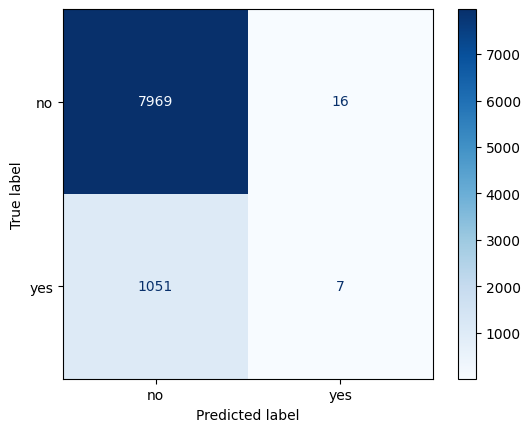

In [15]:
filas = []
for nombre, modelo in [
    ("Siempre no", modelo_referencia),
    ("Regresión logística", modelo_base),
]:
    prediccion = modelo.predict(X_prueba)
    probabilidad = modelo.predict_proba(X_prueba)[:, 1]
    filas.append({
        "modelo": nombre,
        "exactitud": accuracy_score(y_prueba, prediccion),
        "precision_yes": precision_score(y_prueba, prediccion, zero_division=0),
        "recall_yes": recall_score(y_prueba, prediccion, zero_division=0),
        "f1_yes": f1_score(y_prueba, prediccion, zero_division=0),
        "AP": average_precision_score(y_prueba, probabilidad),
    })

resultados = pd.DataFrame(filas).set_index("modelo")
display(resultados.round(3))

pred_base = modelo_base.predict(X_prueba)
print("Matriz de confusión (filas: real 0/1; columnas: predicho 0/1):")
print(confusion_matrix(y_prueba, pred_base))
ConfusionMatrixDisplay.from_predictions(
    y_prueba, pred_base, display_labels=["no", "yes"],
    values_format="d", cmap="Blues"
)
plt.show()

In [16]:
# Priorizar al 10 % de clientes con mayor probabilidad estimada
probabilidades = modelo_base.predict_proba(X_prueba)[:, 1]
n_top = int(len(X_prueba) * 0.10)
indices_top = np.argsort(probabilidades)[-n_top:]
contrataciones_top = y_prueba.iloc[indices_top].sum()
tasa_top = y_prueba.iloc[indices_top].mean()
tasa_general = y_prueba.mean()

print("Clientes priorizados:", n_top)
print("Contrataciones observadas en ese grupo:", contrataciones_top)
print("Tasa de contratación en el grupo:", round(tasa_top * 100, 2), "%")
print("Tasa de contratación general:", round(tasa_general * 100, 2), "%")
print("Mejora relativa (lift):", round(tasa_top / tasa_general, 2), "veces")

Clientes priorizados: 904
Contrataciones observadas en ese grupo: 297
Tasa de contratación en el grupo: 32.85 %
Tasa de contratación general: 11.7 %
Mejora relativa (lift): 2.81 veces


### Interpretación

La regla de predecir siempre `no` obtuvo 88.3 % de exactitud, pero **no identificó ningún cliente que sí contrató**. La regresión logística alcanzó 88.2 % de exactitud, 30.4 % de precisión y apenas 0.7 % de recall para `yes` con el umbral de 0.5: detectó 7 de 1,058 contrataciones y dejó pasar 1,051. Por ello, ese umbral no sirve para decidir directamente a quién llamar.

La **precisión promedio (AP)** de la regresión logística fue 0.255, frente a 0.117 de la regla mayoritaria. Esto indica que las probabilidades contienen señal útil para ordenar clientes. Al seleccionar el **10 % con mayor probabilidad estimada** (904 clientes), 297 habían contratado: una tasa observada de **32.85 %**, frente al **11.70 %** general, equivalente a **2.81 veces** la tasa promedio. En este ejercicio, el modelo es más útil como *ranking* de priorización que como clasificador con umbral 0.5.

Estos resultados provienen de registros históricos de clientes contactados. No demuestran que una llamada cause la contratación ni garantizan el mismo resultado en clientes no contactados.

### 5.1. ¿Podemos mejorar el modelo?

El modelo anterior se conserva como **baseline**. Para una mejora opcional, se separa una validación estratificada del conjunto de entrenamiento; el conjunto de prueba no participa en la elección. Comparamos la regresión logística original, una versión con pesos de clase y un modelo de árboles con gradient boosting. Se elige por precisión promedio (AP) en validación, y se informa también la tasa observada en el 10 % de clientes con mayor puntuación. Esta tasa importa porque el objetivo práctico es priorizar llamadas.

In [17]:
# La validación sale únicamente de los datos de entrenamiento.
X_ajuste, X_val, y_ajuste, y_val = train_test_split(
    X_ent, y_ent, test_size=0.25, random_state=43, stratify=y_ent
)

tipos_categoria = {
    columna: CategoricalDtype(categories=X_ajuste[columna].unique())
    for columna in categoricas
}
def como_categorias(datos):
    copia = datos.copy()
    for columna, tipo in tipos_categoria.items():
        copia[columna] = copia[columna].astype(tipo)
    return copia

candidatos = {
    "Logística original": clone(modelo_base),
    "Logística balanceada": clone(modelo_base).set_params(
        clasificador__class_weight="balanced"
    ),
    "Gradient boosting": HistGradientBoostingClassifier(
        categorical_features="from_dtype", max_iter=150,
        learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=30,
        l2_regularization=1.0, random_state=42
    ),
}
filas_validacion = []
for nombre, candidato in candidatos.items():
    datos_ajuste = como_categorias(X_ajuste) if nombre == "Gradient boosting" else X_ajuste
    datos_val = como_categorias(X_val) if nombre == "Gradient boosting" else X_val
    candidato.fit(datos_ajuste, y_ajuste)
    puntuaciones = candidato.predict_proba(datos_val)[:, 1]
    n_priorizados = max(1, int(len(puntuaciones) * 0.10))
    mejores = np.argsort(puntuaciones)[-n_priorizados:]
    filas_validacion.append({
        "modelo": nombre,
        "AP_validacion": average_precision_score(y_val, puntuaciones),
        "tasa_top10_validacion": y_val.iloc[mejores].mean(),
        "lift_top10_validacion": y_val.iloc[mejores].mean() / y_val.mean(),
    })
resultados_validacion = pd.DataFrame(filas_validacion).set_index("modelo")
display(resultados_validacion.sort_values("AP_validacion", ascending=False).round(4))

,AP_validacion,tasa_top10_validacion,lift_top10_validacion
modelo,,,
Gradient boosting,0.3561,0.4580,3.9139
Logística original,0.2665,0.3407,2.9118
Logística balanceada,0.2564,0.3274,2.7984


In [18]:
# Selección realizada únicamente con la validación.
nombre_ganador = resultados_validacion["AP_validacion"].idxmax()
modelo_mejorado = clone(candidatos[nombre_ganador])

if nombre_ganador == "Gradient boosting":
    tipos_finales = {
        columna: CategoricalDtype(categories=X_ent[columna].unique())
        for columna in categoricas
    }
    def preparar_final(datos):
        copia = datos.copy()
        for columna, tipo in tipos_finales.items():
            copia[columna] = copia[columna].astype(tipo)
        return copia
    X_ent_final = preparar_final(X_ent)
    X_prueba_final = preparar_final(X_prueba)
else:
    X_ent_final, X_prueba_final = X_ent, X_prueba

modelo_mejorado.fit(X_ent_final, y_ent)
proba_mejorada = modelo_mejorado.predict_proba(X_prueba_final)[:, 1]
pred_mejorada = (proba_mejorada >= 0.50).astype(int)
n_top_prueba = max(1, int(len(proba_mejorada) * 0.10))
mejores_prueba = np.argsort(proba_mejorada)[-n_top_prueba:]
tasa_top_mejorada = float(y_prueba.iloc[mejores_prueba].mean())

comparacion_prueba = pd.DataFrame({
    "Logística baseline": {
        "AP": float(resultados.loc["Regresión logística", "AP"]),
        "tasa_top10": float(tasa_top),
        "lift_top10": float(tasa_top / tasa_general),
        "precision_yes_0.5": float(resultados.loc["Regresión logística", "precision_yes"]),
        "recall_yes_0.5": float(resultados.loc["Regresión logística", "recall_yes"]),
    },
    nombre_ganador: {
        "AP": float(average_precision_score(y_prueba, proba_mejorada)),
        "tasa_top10": tasa_top_mejorada,
        "lift_top10": tasa_top_mejorada / float(y_prueba.mean()),
        "precision_yes_0.5": float(precision_score(y_prueba, pred_mejorada, zero_division=0)),
        "recall_yes_0.5": float(recall_score(y_prueba, pred_mejorada, zero_division=0)),
    },
}).T
print("Modelo elegido en validación:", nombre_ganador)
display(comparacion_prueba.round(4))
print("Matriz de confusión del modelo mejorado:")
print(confusion_matrix(y_prueba, pred_mejorada))

Modelo elegido en validación: Gradient boosting


,AP,tasa_top10,lift_top10,precision_yes_0.5,recall_yes_0.5
Logística baseline,0.2550,0.3285,2.8081,0.3043,0.0066
Gradient boosting,0.3472,0.4148,3.5456,0.6042,0.1096


Matriz de confusión del modelo mejorado:
[[7909   76]
 [ 942  116]]


In [19]:
# El umbral se elige con la validación, nunca con la prueba.
p_val_ganador = candidatos[nombre_ganador].predict_proba(
    como_categorias(X_val) if nombre_ganador == "Gradient boosting" else X_val
)[:, 1]
prec_val, rec_val, umbrales = precision_recall_curve(y_val, p_val_ganador)
f1_por_umbral = 2 * prec_val[:-1] * rec_val[:-1] / (
    prec_val[:-1] + rec_val[:-1] + 1e-12
)
indice_umbral = int(np.argmax(f1_por_umbral))
umbral_validado = float(umbrales[indice_umbral])
pred_umbral = (proba_mejorada >= umbral_validado).astype(int)

print("Umbral elegido en validación:", round(umbral_validado, 4))
print("F1 de validación en ese umbral:", round(float(f1_por_umbral[indice_umbral]), 4))
display(pd.DataFrame({
    "umbral_0.5": {
        "precision_yes": precision_score(y_prueba, pred_mejorada, zero_division=0),
        "recall_yes": recall_score(y_prueba, pred_mejorada, zero_division=0),
        "f1_yes": f1_score(y_prueba, pred_mejorada, zero_division=0),
        "positivos_predichos": int(pred_mejorada.sum()),
    },
    "umbral_validado": {
        "precision_yes": precision_score(y_prueba, pred_umbral, zero_division=0),
        "recall_yes": recall_score(y_prueba, pred_umbral, zero_division=0),
        "f1_yes": f1_score(y_prueba, pred_umbral, zero_division=0),
        "positivos_predichos": int(pred_umbral.sum()),
    },
}).T.round(4))
print("Matriz de confusión con umbral validado:")
print(confusion_matrix(y_prueba, pred_umbral))

Umbral elegido en validación: 0.2127
F1 de validación en ese umbral: 0.4244


,precision_yes,recall_yes,f1_yes,positivos_predichos
umbral_0.5,0.6042,0.1096,0.1856,192.0
umbral_validado,0.3931,0.3790,0.3859,1020.0


Matriz de confusión con umbral validado:
[[7366  619]
 [ 657  401]]


**Interpretación de la mejora.** El gradient boosting se eligió por su AP en validación (0.356, frente a 0.267 de la logística original). En prueba, su AP fue **0.347** frente a **0.255** del baseline. Al priorizar 904 clientes (10 %), la tasa observada de contratación pasó de **32.85 % a 41.48 %**: aproximadamente 375 contrataciones en ese grupo, con un lift de 3.55 frente a 2.81. Con el umbral de 0.5 detectó 116 de 1,058 contrataciones (recall 10.96 %) y tuvo precisión de 60.42 % entre los predichos positivos; aún dejó pasar 942. Por ello, la mejora es relevante para ordenar llamadas, pero el umbral de 0.5 sigue siendo limitado. No se ajustaron parámetros ni se eligió el algoritmo usando los resultados de prueba. La comparación no prueba que llamar a esos clientes cause la contratación.

**Umbral de decisión.** El umbral de **0.2127** se seleccionó para maximizar F1 en validación, sin consultar las etiquetas de prueba. En prueba, la precisión fue **39.31 %**, el recall **37.90 %** y F1 **0.386**: detectó 401 contrataciones, generó 619 falsos positivos y aún omitió 657 casos positivos. Con 0.5 la precisión era mayor (60.42 %), pero solo detectaba 116 contrataciones. Si existe un límite fijo de llamadas, resulta más directo seleccionar los clientes con mayor probabilidad hasta cubrir ese cupo; el umbral validado ilustra cómo cambian los errores cuando se busca mayor cobertura.

## 6. Registro del experimento en MLflow

Se registran la configuración del modelo, la división de datos y las métricas de prueba del baseline. El seguimiento usa una base SQLite local en Colab; como la sesión es temporal, la captura de la interfaz debe guardarse antes de cerrar el entorno. Las métricas de priorización se incluyen porque responden al objetivo de decidir a quién llamar.

In [20]:
mlflow.set_tracking_uri("sqlite:////content/mlflow.db")
mlflow.set_experiment("Bank Marketing - baseline")

parametros = {
    "fuente": "UCI bank-full.csv",
    "objetivo": "y: contratacion del deposito",
    "modelo": "regresion logistica",
    "test_size": 0.20,
    "random_state": 42,
    "estratificacion": True,
    "solver": "liblinear",
    "max_iter": 1000,
    "umbral_clasificacion": 0.50,
    "fraccion_priorizada": 0.10,
    "columnas_excluidas": ",".join(columnas_excluir),
    "unknown_job_education": "categoria explicita",
    "outliers": "conservados tras revision",
}
metricas = {clave: float(valor) for clave, valor in
            resultados.loc["Regresión logística"].items()}
metricas.update({
    "tasa_top10": float(tasa_top),
    "tasa_general": float(tasa_general),
    "lift_top10": float(tasa_top / tasa_general),
    "clientes_top10": int(n_top),
    "contrataciones_top10": int(contrataciones_top),
    "n_entrenamiento": int(len(X_ent)),
    "n_prueba": int(len(X_prueba)),
})

with mlflow.start_run(run_name="logistica_baseline_prellamada") as corrida:
    mlflow.log_params(parametros)
    mlflow.log_metrics(metricas)
    mlflow.sklearn.log_model(modelo_base, name="modelo_base",
                             serialization_format="cloudpickle")
    run_id = corrida.info.run_id

print("Experimento:", mlflow.get_experiment_by_name("Bank Marketing - baseline").name)
print("Run ID:", run_id)
print("Métricas registradas:")
display(pd.Series(metricas).round(4))

2026/10/05 05:27:44 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/05 05:27:44 INFO mlflow.store.db.utils: Updating database tables
2026/10/05 05:27:52 INFO mlflow.tracking.fluent: Experiment with name 'Bank Marketing - baseline' does not exist. Creating a new experiment.
2026/10/05 05:27:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Experimento: Bank Marketing - baseline
Run ID: 3766ef777d8d4c3c943be3801a4692d1
Métricas registradas:


,0
exactitud,0.8820
precision_yes,0.3043
recall_yes,0.0066
f1_yes,0.0130
AP,0.2550
tasa_top10,0.3285
tasa_general,0.1170
lift_top10,2.8081
clientes_top10,904.0000
contrataciones_top10,297.0000


In [21]:
# Autorizar únicamente el host del proxy asignado a esta sesión de Colab.
proxy_url = output.eval_js("google.colab.kernel.proxyPort(5000)")
proxy_host = urlparse(proxy_url).hostname
if "mlflow_ui" in globals() and mlflow_ui.poll() is None:
    mlflow_ui.terminate()
    mlflow_ui.wait(timeout=10)

mlflow_ui = subprocess.Popen(
    ["mlflow", "ui", "--backend-store-uri", "sqlite:////content/mlflow.db",
     "--host", "0.0.0.0", "--port", "5000",
     "--allowed-hosts", f"{proxy_host},localhost:*",
     "--cors-allowed-origins", f"https://{proxy_host},https://colab.research.google.com"],
    stdout=open("/content/mlflow_ui.log", "w"),
    stderr=subprocess.STDOUT,
)
print("Host autorizado:", proxy_host)
print("Proceso de MLflow UI:", mlflow_ui.pid)
output.serve_kernel_port_as_window(5000)

Host autorizado: 5000-m-s-kkb-use1d1-uitkozjhpwhw-d.us-east1-1.prod.colab.dev
Proceso de MLflow UI: 2972
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [22]:
# Verificación independiente de la interfaz: leer la corrida desde MLflow Tracking.
registro = mlflow.get_run(run_id)
print("Run ID:", registro.info.run_id)
print("Estado:", registro.info.status)
print("Parámetros guardados:", len(registro.data.params))
print("Métricas guardadas:", len(registro.data.metrics))
display(pd.Series({
    "modelo": registro.data.params["modelo"],
    "test_size": registro.data.params["test_size"],
    "solver": registro.data.params["solver"],
    "AP": registro.data.metrics["AP"],
    "recall_yes": registro.data.metrics["recall_yes"],
    "tasa_top10": registro.data.metrics["tasa_top10"],
    "lift_top10": registro.data.metrics["lift_top10"],
}, name="corrida final"))

Run ID: 3766ef777d8d4c3c943be3801a4692d1
Estado: FINISHED
Parámetros guardados: 13
Métricas guardadas: 12


,corrida final
modelo,regresion logistica
test_size,0.2
solver,liblinear
AP,0.254992
recall_yes,0.006616
tasa_top10,0.32854
lift_top10,2.808115


### 6.1. Corrida adicional: modelo mejorado

El baseline permanece identificado como tal. Se registra por separado el modelo seleccionado con la validación, su umbral y sus métricas de validación y prueba. Esto permite comparar ambas corridas en MLflow sin sobrescribir el resultado original.

In [23]:
parametros_mejorados = {
    "fuente": "UCI bank-full.csv",
    "objetivo": "y: contratacion del deposito",
    "modelo": nombre_ganador,
    "seleccion": "AP en validacion estratificada",
    "test_size": 0.20,
    "validation_size_entrenamiento": 0.25,
    "random_state_division": 42,
    "random_state_validacion": 43,
    "max_iter": 150,
    "learning_rate": 0.05,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 30,
    "umbral_validado": round(umbral_validado, 6),
    "columnas_excluidas": ",".join(columnas_excluir),
}
metricas_mejoradas = {
    "AP": float(comparacion_prueba.loc[nombre_ganador, "AP"]),
    "AP_validacion": float(resultados_validacion.loc[nombre_ganador, "AP_validacion"]),
    "tasa_top10": float(comparacion_prueba.loc[nombre_ganador, "tasa_top10"]),
    "tasa_top10_validacion": float(resultados_validacion.loc[nombre_ganador, "tasa_top10_validacion"]),
    "lift_top10": float(comparacion_prueba.loc[nombre_ganador, "lift_top10"]),
    "precision_yes": float(precision_score(y_prueba, pred_mejorada, zero_division=0)),
    "recall_yes": float(recall_score(y_prueba, pred_mejorada, zero_division=0)),
    "f1_yes": float(f1_score(y_prueba, pred_mejorada, zero_division=0)),
    "precision_yes_umbral": float(precision_score(y_prueba, pred_umbral, zero_division=0)),
    "recall_yes_umbral": float(recall_score(y_prueba, pred_umbral, zero_division=0)),
    "f1_yes_umbral": float(f1_score(y_prueba, pred_umbral, zero_division=0)),
    "n_entrenamiento": int(len(X_ent)),
    "n_prueba": int(len(X_prueba)),
}
with mlflow.start_run(run_name="gradient_boosting_mejorado") as corrida_mejorada:
    mlflow.log_params(parametros_mejorados)
    mlflow.log_metrics(metricas_mejoradas)
    mlflow.sklearn.log_model(modelo_mejorado, name="modelo_mejorado",
                             serialization_format="cloudpickle")
    run_id_mejorado = corrida_mejorada.info.run_id
print("Run ID mejorado:", run_id_mejorado)
print("Estado:", mlflow.get_run(run_id_mejorado).info.status)
display(pd.Series(metricas_mejoradas).round(4))

2026/10/05 05:28:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Run ID mejorado: 87f546a37c694d1590cbb231cc772d80
Estado: FINISHED


,0
AP,0.3472
AP_validacion,0.3561
tasa_top10,0.4148
tasa_top10_validacion,0.4580
lift_top10,3.5456
precision_yes,0.6042
recall_yes,0.1096
f1_yes,0.1856
precision_yes_umbral,0.3931
recall_yes_umbral,0.3790


In [24]:


# Copia consistente de SQLite y artefactos para conservar el experimento.
base_exportada = Path("/content/mlflow_export.db")
with sqlite3.connect("/content/mlflow.db") as origen, sqlite3.connect(base_exportada) as destino:
    origen.backup(destino)

paquete = Path("/content/mlflow_evidencia.zip")
with ZipFile(paquete, "w", compression=ZIP_DEFLATED) as archivo:
    archivo.write(base_exportada, arcname="mlflow.db")
    for ruta in Path("/content/mlruns").rglob("*"):
        if ruta.is_file():
            archivo.write(ruta, arcname=ruta.relative_to("/content"))
print("Evidencia lista:", paquete.name, f"({paquete.stat().st_size / 1024 / 1024:.2f} MB)")
print("Descárgala desde el panel Archivos de Colab antes de cerrar la sesión.")

Evidencia lista: mlflow_evidencia.zip (0.13 MB)
Descárgala desde el panel Archivos de Colab antes de cerrar la sesión.


## 7. Reflexión sobre MLOps

Este ejercicio me permitió recorrer el flujo completo de un proyecto de aprendizaje automático y comprobar que la calidad de la entrega no depende solo de la exactitud del modelo. Al explorar los datos encontré una clase positiva minoritaria, categorías `unknown` y valores extremos que requerían decisiones explícitas. También confirmé que una variable aparentemente muy útil, como la duración de la llamada, no estaría disponible al momento de decidir a qué cliente llamar. Incluirla habría producido una evaluación engañosa. La división estratificada, la preparación dentro de un `Pipeline` y la comparación con una regla simple hicieron más clara la interpretación de los resultados.

Para mejorar este trabajo con prácticas de MLOps, primero automatizaría las validaciones del esquema, los rangos y la proporción de categorías desconocidas cada vez que lleguen nuevos datos. Después versionaría el dataset, el código y el entorno para poder repetir exactamente cada corrida. Mantendría en MLflow los parámetros, las métricas y el modelo, y agregaría pruebas automáticas antes de publicar una nueva versión. En producción vigilaría si cambian la distribución de los clientes, la tasa real de contratación y el desempeño del ranking; también definiría cuándo reentrenar y quién revisa los resultados.

En mi ámbito profesional, estas prácticas ayudan a que una recomendación basada en datos sea verificable y útil para tomar decisiones. Aquí el umbral de 0.5 casi no identificó contrataciones, mientras que el 10 % de clientes con mayor puntuación mostró una tasa observada más alta. Esto enseña a elegir métricas según la decisión concreta, comunicar límites del modelo y evitar que una cifra atractiva oculte errores operativos. En mi ambito profesional (QA Autation Software Developer) podria traducir esto a en que escenarios normalmente encontramos mas fallas, a que podriamos darle prioridad e intentar predecir fallas para reportarlas lo antes posible.